# Introduction

In this assignment, we want to perform an Exploratory Data Analysis (EDA) on NASA's Planetary Systems dataset. This dataset contains observations of individual exoplanets and the planetary systems they reside within.

A sophisticated browser for the dataset is located at https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=PS. However, since many datasets don't provide such features, we'll try to make as little use as possible of the features of NASA's specific dataset, and instead use Python techniques for handling datasets.

To begin, we import the packages we'll need:
- `pandas` contains the bulk of the data storage and manipulation tools we'll use.
- `numpy` lets us perform complex mathematical operations on our data.
- `requests` allows us to make HTTP requests to access data on the web.
- `io` lets us convert HTTP responses into IO streams readable by `pandas`.
- `matplotlib.pyplot` provides a base library for displaying data plots graphically.
- `seaborn` provides a more user-friendly interface for `matplotlib.pyplot`.

In [1]:
import pandas as pd
import numpy as np
import requests
import io
import matplotlib.pyplot as plt
import seaborn as sns

# Downloading and Importing the Dataset

We specify the URL we'll download the data from, and the SQL query we'll use. NASA's datasets use the TAP API, which allows us to specify an SQL query and download the data returned by that SQL query in CSV format. However, since we want to work exclusively in Python, we'll select all columns from the dataset, where `default_flag = 1`. `default_flag` is a parameter provided by NASA to remove duplicate entries for the same planetary system observed at different points in time, with `default_flag` being set to `1` on the most up to date row for each planetary system.

In [2]:
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
query = "SELECT * FROM ps WHERE default_flag = 1"

Now, we perform the HTTP request and read the returned CSV data into a Pandas `DataFrame`.

In [3]:
response = requests.get(url, params={"query": query, "format": "csv"})
planetary_systems = pd.read_csv(io.StringIO(response.text))

C:\Users\retro\AppData\Local\Temp\ipykernel_17564\2078703534.py:2: DtypeWarning: Columns (184: pl_trueobliqstr) have mixed types. Specify dtype option on import or set low_memory=False.
  planetary_systems = pd.read_csv(io.StringIO(response.text))


Despite the warning, it worked! Note that Pandas warns us that one of the columns, "pl_trueobliqstr", has a mixed datatype. Before we investigate that, let's get an overview of the dataset we just downloaded.

In [4]:
print(planetary_systems.info())

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Columns: 355 entries, pl_name to sy_kmagerr2
dtypes: float64(239), int64(26), str(90)
memory usage: 30.9 MB
None


# Selecting and Trimming the Data

The DataFrame has 6445 rows, which is the same as we see on the online navigator after setting Default Parameter Set to 1 (`default_flag = 1`). It also has 355 columns, which are significantly more than we see on the online navigator. This is far too much data to work with all at once, so we should try to trim it first.

## Deciding which Columns to Keep

Let's first try to cut down on the number of columns by limiting it only to the columns we see online. The online navigator shows the following columns:
- Planet Name
- Host Name
- Default Parameter Set
- Number of Stars
- Number of Planets
- Discovery Method
- Discovery Year
- Discovery Facility
- Solution Type
- Controversial Flag
- Planetary Parameter Reference
- Orbital Period \[days\]
- Orbit Semi-Major Axis \[au\]
- Planet Radius \[Earth Radius\]
- Planet Radius \[Jupiter Radius\]
- Planet Mass or Mass*sin(i) \[Earth Mass\]
- Planet Mass or Mass*sin(i) \[Jupiter Mass\]
- Planet Mass or Mass*sin(i) Provenance
- Eccentricity
- Insolation Flux \[Earth Flux\]
- Equilibrium Temperature \[K\]
- Data show Transit Timing Variations
- Stellar Parameter Reference
- Spectral Type
- Stellar Effective Temperature \[K\]
- Stellar Radius \[Solar Radius\]
- Stellar Mass \[Solar Mass\]
- Stellar Metallicity \[dex\]
- Stellar Metallicity Ratio
- Stellar Surface Gravity \[log10(cm/s**2)\]
- System Parameter Reference
- RA \[sexagesimal\]
- Dec \[sexagesimal\]
- Distance \[pc\]
- V (Johnson) Magnitude
- Ks (2MASS) Magnitude
- Gaia Magnitude
- Date of Last Update
- Planetary Parameter Reference Publication Date
- Release Date

This gives us a total of 40 columns. Still a lot, but nowhere near 355.

From here, let's decide what data we can't use:
- Default Parameter Set: This is the aforementioned `default_flag` column. We don't need to keep this in our DataFrame after having made the query.
- Discovery Year: This gives the year the planetary system was first observed. It only gives the year, and we can get more specific datetime data from the Date of Last Update column.
- Solution Type: According to the online navigator, this column has three possible values: "Published Confirmed" (for all but 74 rows), "Kepler Project Candidate" or "TESS Project Candidate".
- Controversial Flag: This likely indicates statistical outliers in the dataset, and only 58 rows have it set to 1. We'll determine outliers in the data ourselves, so this can be removed.
- Planetary Parameter Reference: This column provides links to the papers in which the data for the given planet was collected.
- Planet Mass or Mass*sin(i) Provenance: This column outlines the method used to estimate planet mass in cases where the planet mass couldn't be observed directly due to the angle of observation. This can be removed, as we expect all data to be approximative anyway.
- Data show Transit Timing Variations: This column is either 0 or 1, depending on whether the data "shows transit timing variations." I don't really know what this means and I don't particularly care to find out.
- Stellar Parameter Reference: This column provides links to the papers in which the data for the star or stars of the system was collected.
- System Parameter Reference: This column provides links to the papers in which the data for the planetary system as a whole was collected.
- Planetary Parameter Reference Publication Date: Since we're removing all of the reference links, we don't particularly care about this column.
- Release Date: Since the parameters may have been updated since, we only care about the Date of Last Update.

Additionally, let's decide what data we don't *want* to use, since they require somewhat technical knowledge that lies outside the scope of this course:
- Planet Radius \[Earth Radius\]: We only need one unit of measurement, so we'll go with Jupiter Radius since that's more standard.
- Planet Mass or Mass*sin(i) \[Earth Mass\]: -||-
- Insolation Flux \[Earth Flux\]: This measures the flux of energy that is transmitted to the exoplanet from its star.
- Equilibrium Temperature \[K\]: This represents a theoretical temperature that a planet would absorb in a vacuum as the energy from its star passes through it.
- Stellar Metallicity \[dex\]: This measures the proportion of heavier elements within a star to Hydrogen and Helium, which correlates to how much nuclear fusion takes place within the star.
- Stellar Metallicity Ratio: This is the ratio of particular elements by which stellar metallicity was estimated.
- RA \[sexagesimal\]: Right Ascension (RA) measures the east-west position of the planetary system from the viewpoint of Earth.
- Dec \[sexagesimal\]: Declination (Dec) measures the north (+) or south (-) position of the planetary system from the viewpoint of Earth.
- V (Johnson) Magnitude: Measures how much yellow-green light is emitted by the star/stars.
- Ks (2MASS) Magnitude: Measures how much infrared light is emitted by the star/stars.
- Gaia Magnitude: Measures how much blue and red light is emitted by the star/stars.

This leave us with the following columns we want to keep:
- Planet Name
- Host Name
- Number of Stars
- Number of Planets
- Discovery Method
- Discovery Facility
- Orbital Period \[days\]
- Orbit Semi-Major Axis \[au\]
- Planet Radius \[Jupiter Radius\]
- Planet Mass or Mass*sin(i) \[Jupiter Mass\]
- Eccentricity
- Spectral Type
- Stellar Effective Temperature \[K\]
- Stellar Radius \[Solar Radius\]
- Stellar Mass \[Solar Mass\]
- Stellar Surface Gravity \[log10(cm/s**2)\]
- Distance \[pc\]
- Date of Last Update

This gives us 18 columns to work with.

Unfortunately, since the online navigator's columns don't directly correspond to the columns present in the CSV version of the dataset, we'll have to analyze each of the columns we want to include one by one to determine which DataFrame columns to keep.

## Determining Individual Column Correspondence

### Planet Name

This tells us the name of the planet observed. All we need to do is locate the DataFrame column which has the same values, as we don't expect to see these values in any other column. Let's check for two values of Planet Name just to make sure, and filter using `loc`.

The syntax `DataFrame.loc[r1, r2]` lets us slice the DataFrame with two ranges: `r1` is a range of rows, and `r2` is a range of columns. Here, we keep all of the rows and select the columns in which `any` row's value `isin` the set `["11 Com b", "11 UMi b"]`, which are two planet names we can see in the online navigator.

In [5]:
print(planetary_systems.loc[:, (planetary_systems.isin(["11 Com b", "11 UMi b"])).any()].head())

         pl_name
0  Kepler-1513 b
1     TOI-4914 b
2      TOI-237 c
3     TOI-1898 b
4    HD 330075 b


This means `pl_name` must be the name of the Planet Name column in the DataFrame. Makes sense.

### Host Name

This tells us the name of the planetary system or "host." We can use the same process to determine which DataFrame column corresponds:

In [6]:
print(planetary_systems.loc[:, (planetary_systems.isin(["11 Com", "11 UMi"])).any()].head())

      hostname
0  Kepler-1513
1     TOI-4914
2      TOI-237
3     TOI-1898
4    HD 330075


This means `hostname` must correspond to the Host Name column.

### Number of Stars

This gives us the number of stars in the system. We cannot use the same method, as it is a simple integer value. However, since we've already figured out Planet Name and Host Name, we can simply check the values against rows with a particular `pl_name`.

Let's collect some examples from the online navigator. We should collect these with a Number of Stars != 1, since 1 is by far the most common value:
- Planet Name "11 Com b" has Number of Stars = 2.
- Planet Name "16 Cyg B b" has Number of Stars = 3. (Wow!)
- Planet Name "18 Del b" has Number of Stars = 2.

In [7]:
row_11_com_b = planetary_systems.loc[planetary_systems["pl_name"] == "11 Com b"]
print(row_11_com_b.loc[:, (row_11_com_b == 2).any()].head())

      sy_snum  st_nrvc  pl_nnotes
5733        2        2          2


This gives us three possible columns: `sy_snum`, `st_nrvc`, and `pl_nnotes`. Hopefully the other examples will help elucidate this.

In [8]:
row_16_cyg_b_b = planetary_systems.loc[planetary_systems["pl_name"] == "16 Cyg B b"]
print(row_16_cyg_b_b.loc[:, (row_16_cyg_b_b == 3).any()].head())

     sy_snum  st_nspec
120        3         3


This gives two possible columns, but only one is the same as the candidates for "11 Com b". Therefore, `sy_snum` must correspond to the Number of Stars.

Let's try the final example, just to make sure.

In [9]:
row_18_del_b = planetary_systems.loc[planetary_systems["pl_name"] == "18 Del b"]
print(row_18_del_b.loc[:, (row_18_del_b == 2).any()].head())

      sy_snum  pl_nnotes
5833        2          2


`sy_snum` is correct yet again. We can infer that `sy_snum` does indeed correspond to the Number of Stars.

Let's clean up these variables, as we don't need to keep these rows as their own variables.

In [10]:
del row_11_com_b
del row_16_cyg_b_b
del row_18_del_b

### Number of Planets

This gives us the number of planets in the system as an integer. We can use the same method as for Number of Stars.

We collect the samples:
- Planet Name "14 Her b" has Number of Planets = 2.
- Planet Name "24 Sex b" has Number of Planets = 2.
- Planet Name "55 Cnc B b" has Number of Planets = 7.

In [11]:
row_14_her_b = planetary_systems.loc[planetary_systems["pl_name"] == "14 Her b"]
row_24_sex_b = planetary_systems.loc[planetary_systems["pl_name"] == "24 Sex b"]
row_55_cnc_b_b = planetary_systems.loc[planetary_systems["pl_name"] == "55 Cnc B b"]

print(row_14_her_b.loc[:, (row_14_her_b == 2).any()].head())
print(row_24_sex_b.loc[:, (row_24_sex_b == 2).any()].head())
print(row_55_cnc_b_b.loc[:, (row_55_cnc_b_b == 7).any()].head())

      sy_pnum
5744        2
      sy_pnum  st_nrvc
3856        2        2
      sy_pnum
1154        7


It seems that `sy_pnum` represents the Number of Planets. This makes sense, and we can start to notice a pattern. It seems column IDs that are prefixed with `sy_` (`sy_snum`, `sy_pnum`) pertain to the planetary system as a whole, while column IDs that are prefixed with `pl_` (`pl_name`) pertain to the individual planet.

Once again, let's clean up the variables.

In [12]:
del row_14_her_b
del row_24_sex_b
del row_55_cnc_b_b

### Discovery Method

This tells us the method by which the planetary system was first discovered. In the online navigator, some values in this column include "Radial Velocity", "Imaging", and "Transit". Let's use the same method as with Planet Name and Host Name.

In [13]:
print(planetary_systems.loc[:, (planetary_systems.isin(["Radial Velocity", "Imaging", "Transit"])).any()].head())

   discoverymethod
0          Transit
1          Transit
2          Transit
3          Transit
4  Radial Velocity


This gives us the `discoverymethod` column. That was easy.

### Discovery Facility

This gives us the facility in which the planetary system was first observed.

Sample values include "Xinglong Station", "Okayama Astrophysical Observatory", and "W. M. Keck Observatory".

In [14]:
print(planetary_systems.loc[:, (planetary_systems.isin(["Xinglong Station", "Okayama Astrophysical Observatory", "W. M. Keck Observatory"])).any()].head())

                                  disc_facility
0                                        Kepler
1  Transiting Exoplanet Survey Satellite (TESS)
2                          La Silla Observatory
3  Transiting Exoplanet Survey Satellite (TESS)
4                          La Silla Observatory


This gives us the column `disc_facility`.

### Orbital Period \[days\]

This gives us the number of Earth days it takes for the planet to orbit its host.

This column is trickier, as the data is not formatted as a float, but instead as a collection of floats with a *nominal value* and either a single margin of error or two margins of error on either side.

To make our lives easier, let's attempt to only extract the nominal value, and hope it appears in its own column of floats in the DataFrame already.

We collect our sample values:
- 11 Com b has a nominal Orbital Period of 323.21 (with error margins of +0.06 and -0.05).
- 11 UMi b has a nominal Orbital Period of 516.21997 (+/-3.20000).
- 14 And b has a nominal Orbital Period of 186.76 (+0.11, -0.12).

In [15]:
row_11_com_b = planetary_systems.loc[planetary_systems["pl_name"] == "11 Com b"]
row_11_umi_b = planetary_systems.loc[planetary_systems["pl_name"] == "11 UMi b"]
row_14_and_b = planetary_systems.loc[planetary_systems["pl_name"] == "14 And b"]

print(row_11_com_b.loc[:, (row_11_com_b == 323.21).any()].head())
print(row_11_umi_b.loc[:, (row_11_umi_b == 516.21997).any()].head())
print(row_14_and_b.loc[:, (row_14_and_b == 186.76).any()].head())

del row_11_com_b
del row_11_umi_b
del row_14_and_b

      pl_orbper
5733     323.21
      pl_orbper
1628  516.21997
      pl_orbper
2281     186.76


Luckily, it seems like such a column does exist! Even with finnicky floating-point comparisons! We are given the column `pl_orbper`.

### Orbit Semi-Major Axis \[au\]

Despite its convoluted name, this column simply represents half of the longest diameter of an elliptical orbit.

This is once again continuous data (as most columns from here on out are), and so once again has error margins. But, like with the last column, we can expect that the nominal values exist as floats in their own column in the DataFrame.

Sample values:
- 11 Com b - 1.178
- 11 UMi b - 1.53
- 14 And b - 0.775

In [16]:
row_11_com_b = planetary_systems.loc[planetary_systems["pl_name"] == "11 Com b"]
row_11_umi_b = planetary_systems.loc[planetary_systems["pl_name"] == "11 UMi b"]
row_14_and_b = planetary_systems.loc[planetary_systems["pl_name"] == "14 And b"]

print(row_11_com_b.loc[:, (row_11_com_b == 1.178).any()].head())
print(row_11_umi_b.loc[:, (row_11_umi_b == 1.53).any()].head())
print(row_14_and_b.loc[:, (row_14_and_b == 0.775).any()].head())

del row_11_com_b
del row_11_umi_b
del row_14_and_b

      pl_orbsmax
5733       1.178
      pl_orbsmax
1628        1.53
      pl_orbsmax
2281       0.775


We get the column `pl_orbsmax`.

### Planet Radius \[Jupiter Radius\]

At this point, the process becomes repetitive, and I won't include code for testing the columns. Quantitative data is to be tested in a manner similar to Orbital Period \[days\] and categorical data is to be tested in a manner similar to Planet Name. The code used for the remaining column tests can be found in `column_test.py`.

This column gives the radius of the planet as a multiple of Earth's radius.

It corresponds to the DataFrame column `pl_radj`.

### Planet Mass or Mass*sin(i) \[Jupiter Mass\]

As it turns out, these two metrics have different columns in the dataset, so we can select only Planet Mass \[Jupiter Mass\] and ignore Mass*sin(i), which gives a lower bound similar to a margin of error for the mass, and is NaN in most rows.

Planet Mass \[Jupiter Mass\] corresponds to the DataFrame column `pl_bmassj`.

### Eccentricity

This column gives a metric which measures how irregular (non-circular) the orbit of a planet is around its host.

It corresponds to the DataFrame column `pl_orbeccen`.

### Spectral Type

This column gives categorical data for the spectral type of a system's star.

It corresponds to the DataFrame column `st_spectype`.

### Stellar Effective Temperature \[K\]

This column gives a theoretical approximation of the temperature of a system's star.

It corresponds to the DataFrame column `st_teff`.

### Stellar Radius \[Solar Radius\]

This column gives the radius of a star in terms of the radius of our Sun.

It corresponds to the DataFrame column `st_rad`.

### Stellar Mass \[Solar Mass\]

This column gives the mass of a star in terms of the mass of our Sun.

It corresponds to the DataFrame column `st_mass`.

### Stellar Surface Gravity \[log10(cm/s**2)\]

This column gives the order of magnitude of a star's surface gravity. The real surface gravity would be 10 raised to the power of this value.

It corresponds to the DataFrame column `st_logg`.

### Distance \[pc\]

This column gives the distance of a system from our system in parsecs, a unit of length equal to roughly 3.26 light-years.

It corresponds to the DataFrame column `sy_dist`.

### Date of Last Update

This column gives the date on which the row was last updated, in YYYY-MM-DD string format.

It corresponds to the DataFrame column `rowupdate`.

## Final Summarized Results of Column Correspondence

- Planet Name: `pl_name`
- Host Name: `hostname`
- Number of Stars: `sy_snum`
- Number of Planets: `sy_pnum`
- Discovery Method: `discoverymethod`
- Discovery Facility: `disc_facility`
- Orbital Period \[days\]: `pl_orbper`
- Orbit Semi-Major Axis \[au\]: `pl_orbsmax`
- Planet Radius \[Jupiter Radius\]: `pl_radj`
- Planet Mass \[Jupiter Mass\]: `pl_bmassj`
- Eccentricity: `pl_orbeccen`
- Spectral Type: `st_spectype`
- Stellar Effective Temperature \[K\]: `st_teff`
- Stellar Radius \[Solar Radius\]: `st_rad`
- Stellar Mass \[Solar Mass\]: `st_mass`
- Stellar Surface Gravity \[log10(cm/s**2)\]: `st_logg`
- Distance \[pc\]: `sy_dist`
- Date of Last Update: `rowupdate`

## Selecting Columns in Pandas

Now, we can simply select these columns in Pandas. Let's also rename the columns to be easier to work with.

In [17]:
print(planetary_systems.info())
columns = [
    "pl_name",
    "hostname",
    "sy_snum",
    "sy_pnum",
    "discoverymethod",
    "disc_facility",
    "pl_orbper",
    "pl_orbsmax",
    "pl_radj",
    "pl_bmassj",
    "pl_orbeccen",
    "st_spectype",
    "st_teff",
    "st_rad",
    "st_mass",
    "st_logg",
    "sy_dist",
    "rowupdate"
]
new_columns = [
    "plnt_name",
    "sys_name",
    "sys_stars",
    "sys_planets",
    "disc_method",
    "disc_facility",
    "plnt_orbit_time",
    "plnt_orbit_radius",
    "plnt_radius",
    "plnt_mass",
    "plnt_eccentricity",
    "star_spectral_type",
    "star_temperature",
    "star_radius",
    "star_mass",
    "star_log_gravity",
    "sys_distance",
    "disc_date"
]
ps = planetary_systems[columns]
ps.columns = new_columns
print(ps.info())

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Columns: 355 entries, pl_name to sy_kmagerr2
dtypes: float64(239), int64(26), str(90)
memory usage: 30.9 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   plnt_name           6445 non-null   str    
 1   sys_name            6445 non-null   str    
 2   sys_stars           6445 non-null   int64  
 3   sys_planets         6445 non-null   int64  
 4   disc_method         6445 non-null   str    
 5   disc_facility       6445 non-null   str    
 6   plnt_orbit_time     6078 non-null   float64
 7   plnt_orbit_radius   3953 non-null   float64
 8   plnt_radius         4822 non-null   float64
 9   plnt_mass           3184 non-null   float64
 10  plnt_eccentricity   2770 non-null   float64
 11  star_spectral_type  1439 non-null   str    
 12  star_temperature    5675 non-null   f

We could have also specified these 18 columns as part of the SQL query given to the API, which would be the better way of doing things, but I want to keep my steps as general as possible, since not every online dataset will provide SQL functionality.

# Formatting Data and Handling NaNs

## Converting Date of Last Update to `datetime`

Our `disc_date` column is currently of type `str`, as we can see in `ps.info()`. Let's convert it to proper `datetime` objects instead.

In [18]:
ps["disc_date"] = pd.to_datetime(ps["disc_date"])
print(ps.info())

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   plnt_name           6445 non-null   str           
 1   sys_name            6445 non-null   str           
 2   sys_stars           6445 non-null   int64         
 3   sys_planets         6445 non-null   int64         
 4   disc_method         6445 non-null   str           
 5   disc_facility       6445 non-null   str           
 6   plnt_orbit_time     6078 non-null   float64       
 7   plnt_orbit_radius   3953 non-null   float64       
 8   plnt_radius         4822 non-null   float64       
 9   plnt_mass           3184 non-null   float64       
 10  plnt_eccentricity   2770 non-null   float64       
 11  star_spectral_type  1439 non-null   str           
 12  star_temperature    5675 non-null   float64       
 13  star_radius         5605 non-null   float64       
 14  sta

Every other column seems to be in the right format already. Lucky for us!

## Handling NaNs

However, `ps.info()` shows us that several columns contain a considerable number of NaNs. To get a better sense of this, let's count the number of null values per column, rather than the number of non-null values per column.

In [19]:
print(ps.isna().sum())

plnt_name                0
sys_name                 0
sys_stars                0
sys_planets              0
disc_method              0
disc_facility            0
plnt_orbit_time        367
plnt_orbit_radius     2492
plnt_radius           1623
plnt_mass             3261
plnt_eccentricity     3675
star_spectral_type    5006
star_temperature       770
star_radius            840
star_mass              877
star_log_gravity      1133
sys_distance           128
disc_date                1
dtype: int64


Since most of the NaNs are due to missing physical measurements, it would be odd to replace them with a default value, as this could result in the assumption of absurd, physically impossible planets, nor can we appropriately estimate their values from the other data given. Therefore, we must leave them as is, meaning that plots and statistics will omit any rows they do not have sufficient data for. This shouldn't be a big issue, since we have a large number of rows to work with.

However, let us investigate the single instance of a missing `rowupdate` value.

In [20]:
print(ps.loc[ps["disc_date"].isna()])

                plnt_name           sys_name  sys_stars  sys_planets  \
1266  MOA-2009-BLG-319L b  MOA-2009-BLG-319L          1            1   

       disc_method disc_facility  plnt_orbit_time  plnt_orbit_radius  \
1266  Microlensing           MOA              NaN               2.03   

      plnt_radius  plnt_mass  plnt_eccentricity star_spectral_type  \
1266          NaN      0.212                NaN                NaN   

      star_temperature  star_radius  star_mass  star_log_gravity  \
1266               NaN          NaN      0.524               NaN   

      sys_distance disc_date  
1266        7050.0       NaT  


In the online navigator, we see that this row has a Release Date of 2021-02-11, but no Date of Latest Update. Therefore, we can substitute any missing `disc_date`s with `releasedate`.

In [21]:
ps["disc_date"] = ps["disc_date"].fillna(planetary_systems["releasedate"])
print(ps.iloc[1266])

plnt_name             MOA-2009-BLG-319L b
sys_name                MOA-2009-BLG-319L
sys_stars                               1
sys_planets                             1
disc_method                  Microlensing
disc_facility                         MOA
plnt_orbit_time                       NaN
plnt_orbit_radius                    2.03
plnt_radius                           NaN
plnt_mass                           0.212
plnt_eccentricity                     NaN
star_spectral_type                    NaN
star_temperature                      NaN
star_radius                           NaN
star_mass                           0.524
star_log_gravity                      NaN
sys_distance                       7050.0
disc_date             2021-02-11 00:00:00
Name: 1266, dtype: object


# Distributions

First, to get a general sense of how each of the variables are distributed, we can use `DataFrame.describe()`.

In [22]:
print(ps.describe())

         sys_stars  sys_planets  plnt_orbit_time  plnt_orbit_radius  \
count  6445.000000  6445.000000     6.078000e+03        3953.000000   
mean      1.101319     1.753763     4.278155e+03          19.971492   
min       1.000000     1.000000     9.070629e-02           0.004400   
25%       1.000000     1.000000     4.288377e+00           0.053300   
50%       1.000000     1.000000     1.064078e+01           0.116000   
75%       1.000000     2.000000     3.790750e+01           0.830000   
max       4.000000     8.000000     8.040000e+06       19000.000000   
std       0.339066     1.146353     1.595859e+05         403.635855   

       plnt_radius    plnt_mass  plnt_eccentricity  star_temperature  \
count  4822.000000  3184.000000        2770.000000       5675.000000   
mean      0.399878     2.397621           0.145592       5377.790347   
min       0.027639     0.000063           0.000000        415.000000   
25%       0.146311     0.037442           0.000000       4899.000000   


## Planet Radius

The smallest planet in radius is 2.7% the radius of Jupiter, or 30.9% the radius of Earth. This makes sense, since there's a threshold size planets must meet to be classified as planets (hence why Pluto is not considered a planet). Let's see how that cutoff skews the data with a histogram.

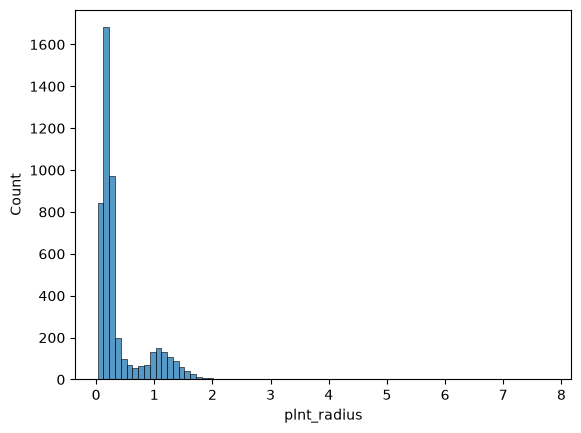

In [23]:
sns.histplot(ps, x="plnt_radius", binwidth=0.1)
plt.show()

The data is very strongly skewed to the left, with the many planets being 10%-20% the size of Jupiter, and the vast majority being up to 2 times the size of Jupiter. To be more precise, from `.describe()` we got that the 1st and 3rd quartiles of planet radii are 0.146 and 0.372, meaning exactly 50% of the planets lie between that range.

However, we know there are outliers present, with some planets being almost 8x the radius of Jupiter. Let's get a better understanding of those outliers with a box plot.

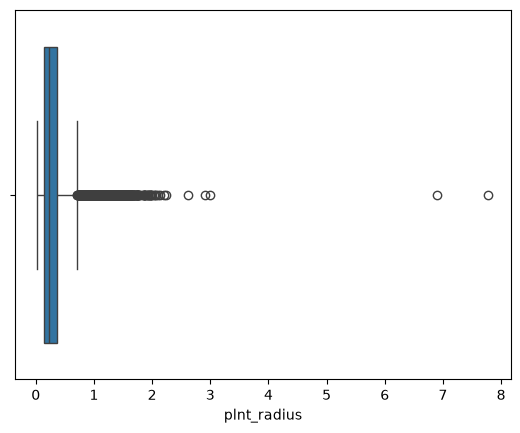

In [24]:
sns.boxplot(ps, x="plnt_radius")
plt.show()

Since the data is so heavily skewed to the left, a lot of the planets that have larger masses but still lie within the primary "curve" of this histogram are displayed as outliers. But we see a cutoff point at around 2.5, with the number of planets whose radii are beyond that being easily visible and countable. Let's look at those specific planets.

In [25]:
print(ps.loc[ps["plnt_radius"] > 2.5])

          plnt_name     sys_name  sys_stars  sys_planets disc_method  \
42         GQ Lup b       GQ Lup          1            1     Imaging   
376     HD 100546 b    HD 100546          1            1     Imaging   
4597  Kepler-1979 b  Kepler-1979          1            1     Transit   
5342   Kepler-297 d   Kepler-297          1            3     Transit   
6281    V2376 Ori b    V2376 Ori          1            1     Imaging   

               disc_facility  plnt_orbit_time  plnt_orbit_radius  plnt_radius  \
42       Paranal Observatory              NaN           100.0000     3.000000   
376      Paranal Observatory              NaN            53.0000     6.900000   
4597                  Kepler        18.508453             0.1383     2.616652   
5342                  Kepler       150.018951             0.5230     2.908382   
6281  Multiple Observatories              NaN            71.0000     7.780000   

      plnt_mass  plnt_eccentricity star_spectral_type  star_temperature  \
42   

The names of these 5 planets are GQ Lup b, HD 100546 b, Kepler-1979 b, Kepler-297 d, and V2376 Ori b. We can make a few observations about these rows:
- Planets with a `disc_method` of Transit seem to be missing data for `plnt_mass` and `star_spectral_type`.
- Planets with a `disc_method` of Imaging seem to be missing data for `plnt_orbit_time`, `plnt_eccentricity`, `star_radius`, and `star_log_gravity`.
- Despite being over 2.5 times Jupiter's radius, the semi-major axes (orbit radii) of Kepler-1979 b and Kepler-297 d are comparatively tiny, with Jupiter's own semi-major axis being almost 5.204 AU (astronomical units). You would expect that larger planets have larger orbits on average, but we can already see that this doesn't seem to be the case (more on this later in the **Correlations** section).

Additionally, only one of these planets has other planets in its system, that being Kepler-297 d. Let's see if its siblings are also in the dataset!

In [26]:
print(ps.loc[ps["sys_name"] == "Kepler-297"])

         plnt_name    sys_name  sys_stars  sys_planets disc_method  \
109   Kepler-297 c  Kepler-297          1            3     Transit   
5342  Kepler-297 d  Kepler-297          1            3     Transit   
5379  Kepler-297 b  Kepler-297          1            3     Transit   

     disc_facility  plnt_orbit_time  plnt_orbit_radius  plnt_radius  \
109         Kepler        74.920137              0.336     0.583000   
5342        Kepler       150.018951              0.523     2.908382   
5379        Kepler        38.871826              0.217     0.256000   

      plnt_mass  plnt_eccentricity star_spectral_type  star_temperature  \
109         NaN                NaN                NaN            5619.0   
5342        NaN                0.0                NaN            5618.0   
5379        NaN                NaN                NaN            5619.0   

      star_radius  star_mass  star_log_gravity  sys_distance  disc_date  
109         0.915        NaN             4.468        692.1

All 3 of them are present. We see that all three were discovered by the Transit method, and only Kepler-297 d is particularly large, with the rest lying within the inter-quartile range of the distribution. We also see that, once again, they are missing several variables, including `plnt_mass`, `plnt_eccentricity`, `star_spectral_type`, and `star_mass`. We also find the claim that Kepler-297 d has "0.0 eccentricity" rather dubious, as that would imply its orbit is a perfect circle. Possible, but unlikely, leading me to believe that this is not the result of a real measurement but rather a placeholder for the insufficient data collected by the Transit method.

Now that we've looked at our outliers, let's zoom in on the range in which most of the planets actually seem to lie.

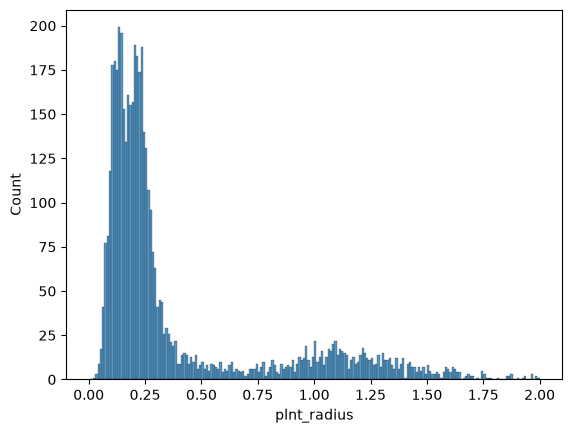

In [27]:
sns.histplot(ps, x="plnt_radius", binrange=(0, 2), binwidth=0.01)
plt.show()

By zooming in, the amount of planets outside the interquartile range seems comparatively far smaller. It also doesn't look like there's a strict cutoff point for how small a planet can be, since the number of planets gradually dies down as the radius approaches 0, rather than there being a clear wall.

To avoid these natural cases of extreme skew, astrophysicists often work with a logarithmic scale rather than a linear scale. Let's apply a base-10 logarithm to our histogram and see if the skew is still present.

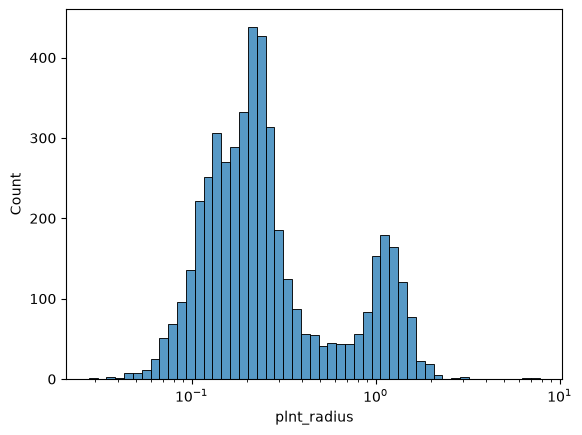

In [28]:
sns.histplot(ps, x="plnt_radius", log_scale=10)
plt.show()

The data seems a lot more normally distributed! However, we now see that the data appears bimodal. This could indicate two separate normal distributions being added together, due to different categorical data like discovery method or discovery facility. We already saw that different discovery methods seem to produce substantially different sets of data, so let's see if that could be the case.

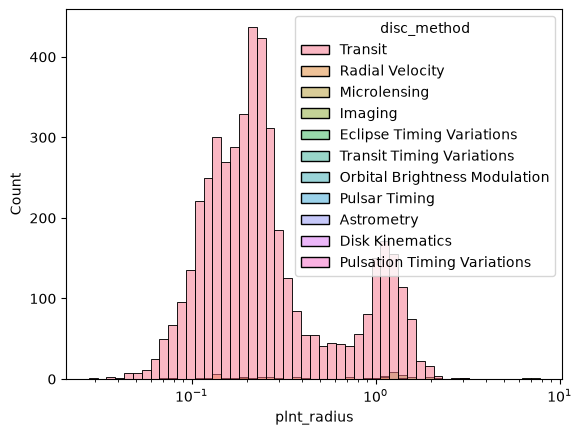

In [29]:
sns.histplot(ps, x="plnt_radius", hue="disc_method", log_scale=10)
plt.show()

As a matter of fact, this doesn't seem to be the case, and the distribution of planets discovered by Transit is still bimodal. It also shows us that the vast majority of rows in the dataset were discovered via Transit.

An alternative hypothesis is that this bimodal distribution is produced by the fact that two distinct types of planets exist, "rocky planets" (like Earth) and "gas giants" (like Jupiter). Unfortunately, data on whether a planet is rocky or gaseous is not included in our dataset, so we can't test this hypothesis.

## Planet Mass

We saw that planet radii are heavily skewed to the left. Let's see if planet masses follow that same pattern.

In [30]:
print(ps["plnt_mass"].describe())

count    3184.000000
mean        2.397621
std         4.689650
min         0.000063
25%         0.037442
50%         0.535097
75%         2.171819
max        30.000000
Name: plnt_mass, dtype: float64


From the quartiles alone, we can see that this likely is the case. The median of 0.535 lies well below the mean of 2.398, and the 75th percentile lies just below it, just like with planet radii.

Let's visualize this.

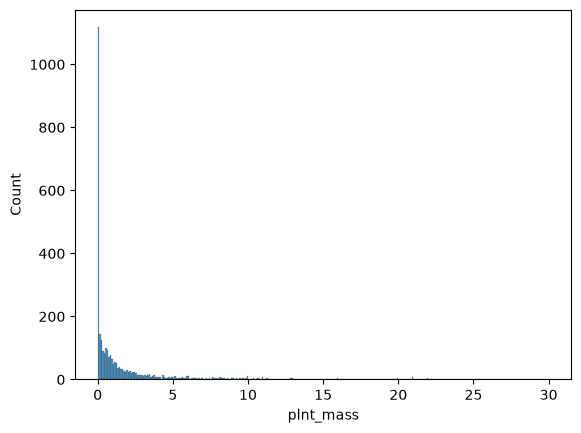

In [31]:
sns.histplot(ps, x="plnt_mass", binwidth=0.1)
plt.show()

At first glance, this actually looks way more skewed than planet radii. However, this might be because the outliers are far more "out there". Let's zoom in and look at only the non-outliers (values within 1.5 * IQR).

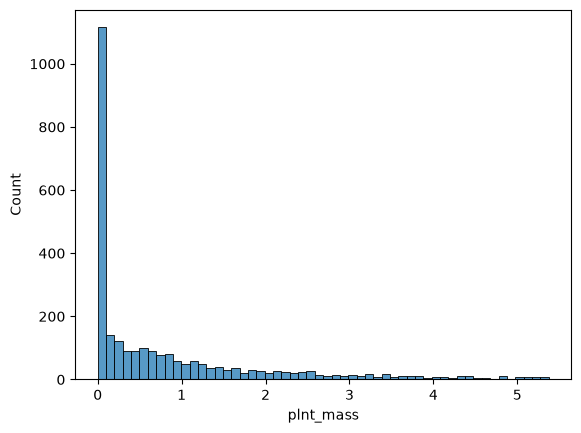

In [32]:
q1 = ps["plnt_mass"].quantile(0.25)
q3 = ps["plnt_mass"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
sns.histplot(ps, x="plnt_mass", binrange=(0, upper), binwidth=0.1)
plt.show()

The data is still extremely skewed. Let's zoom in even further, just to make sure.

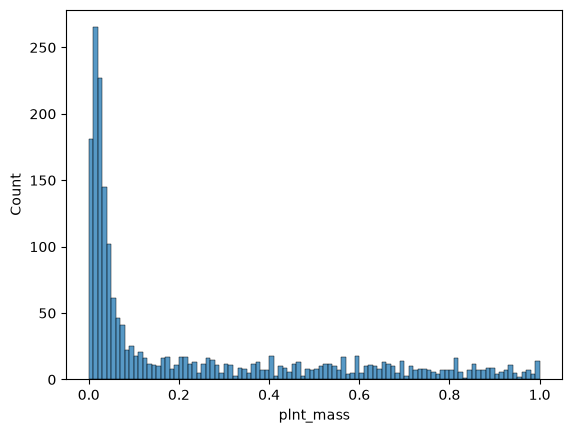

In [33]:
sns.histplot(ps, x="plnt_mass", binrange=(0, 1), binwidth=0.01)
plt.show()

It appears that a majority of planets have a mass between 0.01 and 0.02 of Jupiter's mass, and is even more skewed than planet radii.

Like with planet radius, let's also apply a logarithmic scale to normalize the data.

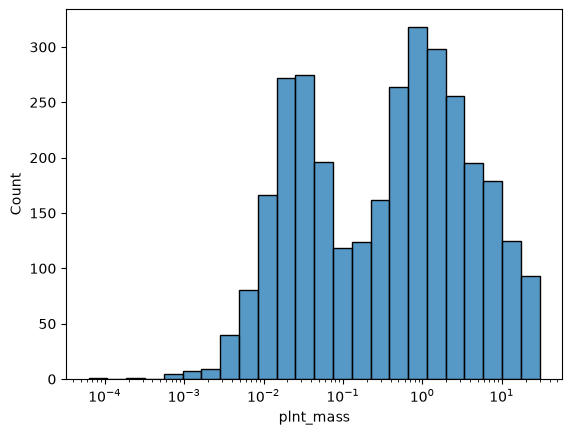

In [34]:
sns.histplot(ps, x="plnt_mass", log_scale=10)
plt.show()

The logarithmic scale reveals that planet mass is also distributed bimodally, just like planet radii.

Interestingly, the logarithmic distribution of planet mass almost suggests a slight *right* skew instead. This is to be expected, since the most massive planet recorded has a mass of 3.0\*10<sup>2</sup> times Jupiter's mass, while the least massive planet recorded has a mass of 6.3\*10<sup>-5</sup>. These lowest values may be outliers on the logarithmic scale, so let's view a boxplot of the logarithmic scale to get a better understanding of the ranges of our data.

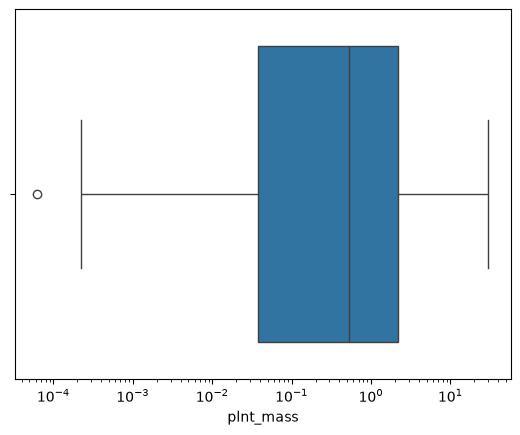

In [35]:
sns.boxplot(ps, x="plnt_mass", log_scale=10)
plt.show()

The right skew appears significant, but not overly so.

## Star Radius

Let's also look at star radii. The distributions given in `ps.describe()` is unreliable, as since each row corresponds to a planet, several rows may represent the same star. We saw this earlier with the Kepler-297 system.

To fix this, let's group by system name. We saw earlier that different rows corresponding to the same system may have different star measurements despite being the same star, so we take the mean of these different values.

In [36]:
stars = ps.groupby("sys_name")[["star_radius", "star_mass", "star_temperature", "star_log_gravity"]].mean()
print(stars.describe())

       star_radius    star_mass  star_temperature  star_log_gravity
count  4177.000000  4435.000000       4275.000000       4020.000000
mean      1.591353     0.949157       5395.671999          4.357735
std       4.111748     0.421039       1350.589754          0.470154
min       0.012300     0.009400        415.000000          0.541000
25%       0.780000     0.770000       4913.500000          4.280000
50%       0.961092     0.951000       5576.000000          4.450000
75%       1.264000     1.110000       5922.333333          4.567025
max      88.475000     9.100000      40000.000000          8.070000


We can see the same patterns we saw with planet radius and planet mass, where the 3rd quartile is just below the mean, and the maximum is a massive outlier. As a matter of fact, the maximum value of 88.475 solar masses is so huge that drawing a histogram with it would be pointless. Let's instead draw a boxplot.

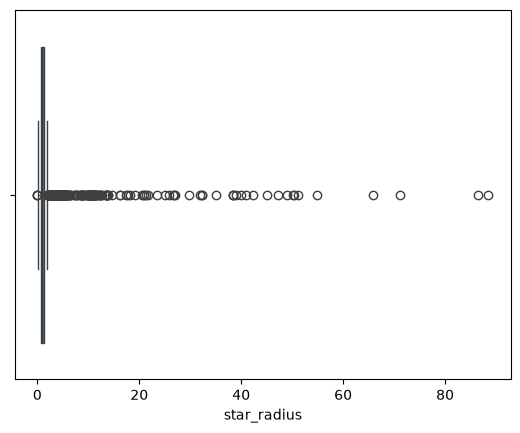

In [37]:
sns.boxplot(stars, x="star_radius")
plt.show()

Unlike with planet radius, there are very many outliers, and the inter-quartile range is minuscule compared to the true scale of the data.

Now let's look at the logarithmic scale.

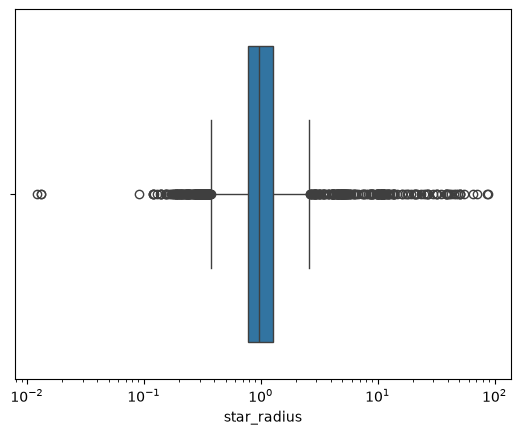

In [38]:
sns.boxplot(stars, x="star_radius", log_scale=10)
plt.show()

That's much better, and the data appears almost perfectly normal. However, there are very many outliers, meaning that the standard deviation of the data is extremely small, despite its range being very large. Let's see what exactly that standard deviation is.

In [39]:
print(np.log10(stars["star_radius"]).describe())

count    4177.000000
mean        0.015125
std         0.293275
min        -1.910095
25%        -0.107905
50%        -0.017235
75%         0.101747
max         1.946821
Name: star_radius, dtype: float64


The standard deviation is 0.293, which is a mere 7.6% of the full range.

Let's also look at a histogram of the data within the interquartile range to get a better understanding of the distribution.

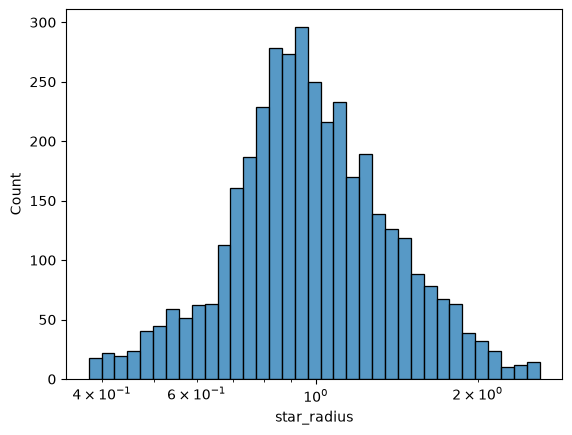

In [40]:
q1 = np.log10(stars["star_radius"]).quantile(0.25)
q3 = np.log10(stars["star_radius"]).quantile(0.75)
lower = q1 - 1.5 * (q3 - q1)
upper = q3 + 1.5 * (q3 - q1)
sns.histplot(stars, x="star_radius", log_scale=10, binrange=(lower, upper))
plt.show()

It seems decently normally distributed, and we can confirm that there's no weird bimodal distribution like what we saw with the planet radii and planet masses.

## Star Mass

Let's look at the description of our star masses again.

In [41]:
print(stars["star_mass"].describe())

count    4435.000000
mean        0.949157
std         0.421039
min         0.009400
25%         0.770000
50%         0.951000
75%         1.110000
max         9.100000
Name: star_mass, dtype: float64


It seems to follow the same pattern as our other logarithmic distributions. Let's see the box plot.

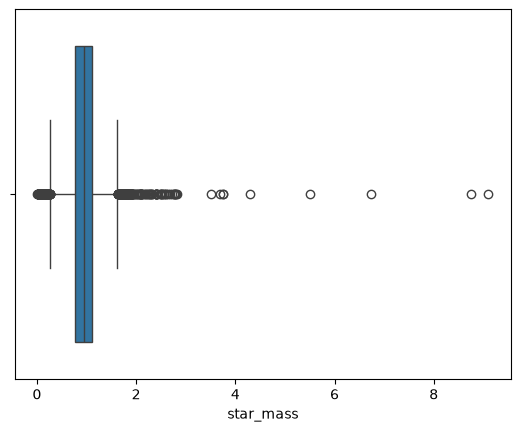

In [42]:
sns.boxplot(stars, x="star_mass")
plt.show()

Business as usual, though notably less extreme outliers than star radii. Let's now look at the boxplot after logarithmic adjustment.

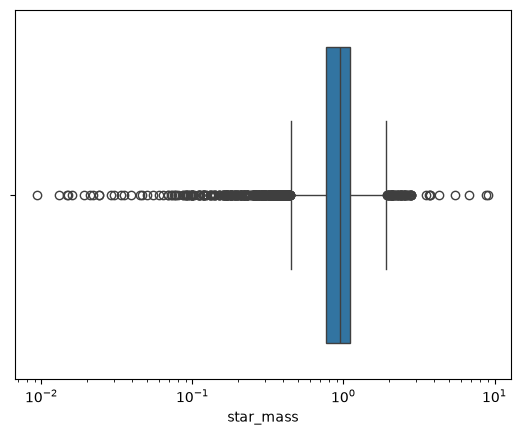

In [43]:
sns.boxplot(stars, x="star_mass", log_scale=10)
plt.show()

Interestingly, like we saw with planet masses, on a logarithmic scale star masses are more right skewed than star radii.

Let's look at the histogram to confirm this.

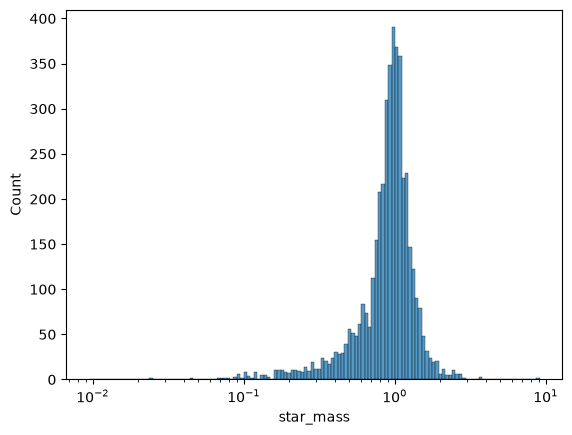

In [44]:
sns.histplot(stars, x="star_mass", log_scale=10)
plt.show()

We'll investigate the correlation between star mass and star radius, as well as the correlation between planet mass and planet radius, in the **Correlations** section.

# Correlations

To get a general sense of how all the different columns correlate to each other, we can use `seaborn`'s `heatmap` to get the correlation coefficient between every pair of variables in a single grid.

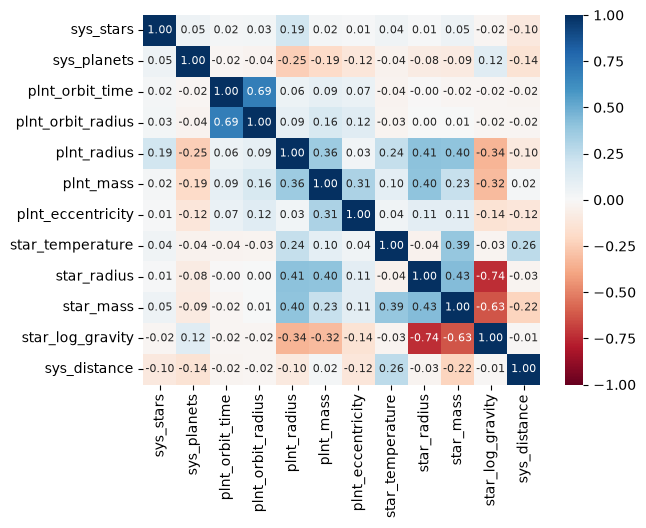

In [45]:
sns.heatmap(ps.corr(numeric_only=True), cmap="RdBu", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.show()

We notice strong positive correlations (r \>= 0.6) between the following variables:
- `plnt_orbit_time` and `plnt_orbit_radius` (0.69)

We notice moderate positive correlations (0.3 \<= r \< 0.6) between the following variables:
- `plnt_radius` and `plnt_mass` (0.36)
- `plnt_radius` and `star_radius` (0.41)
- `plnt_radius` and `star_mass` (0.40)
- `plnt_mass` and `plnt_eccentricity` (0.31)
- `plnt_mass` and `star_radius` (0.40)
- `star_temperature` and `star_mass` (0.39)
- `star_radius` and `star_mass` (0.43)

We notice moderate negative correlations (-0.3 \>= r \> -0.6) between the following variables:
- `plnt_radius` and `star_log_gravity` (-0.34)
- `plnt_mass` and `star_log_gravity` (-0.32)

We notice strong negative correlations (r \<= -0.6) between the following variables:
- `star_radius` and `star_log_gravity` (-0.74)
- `star_mass` and `star_log_gravity` (-0.64)

## Planet Radius vs. Planet Mass

We saw in the **Distributions** section that the distributions of planet radii and planet mass are extremely similar. However, their correlation coefficient, despite indicating a positive correlation, is relatively low.

Let's see this correlation in more detail with a scatter plot.

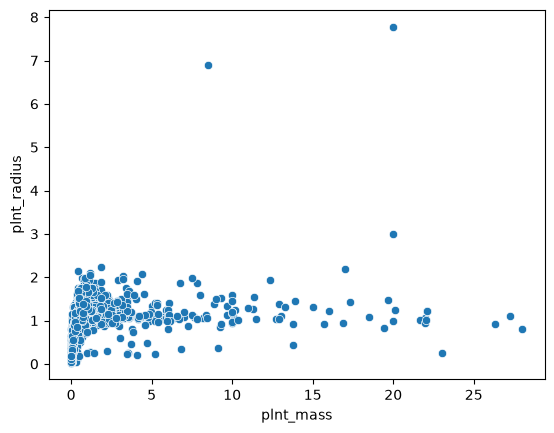

In [46]:
sns.scatterplot(ps, x="plnt_mass", y="plnt_radius")
plt.show()

We notice a particular curve towards the top-left of the graph. This is common amongst data with a logarithmic distribution, confirming that we were correct in the **Distributions** section to look at the data with a logarithmic scale.

Since Seaborn doesn't provide a `log_scale` parameter for scatterplots the same way it did for histograms and box plots, and since we'll want to perform more mathematical operations and analyses on their logarithms, let's save the logarithms of these measurements as new columns in the dataset.

In [47]:
ps["plnt_log_radius"] = np.log10(ps["plnt_radius"])
ps["plnt_log_mass"] = np.log10(ps["plnt_mass"])

Now, let's visualize log10(mass) vs. log10(radius).

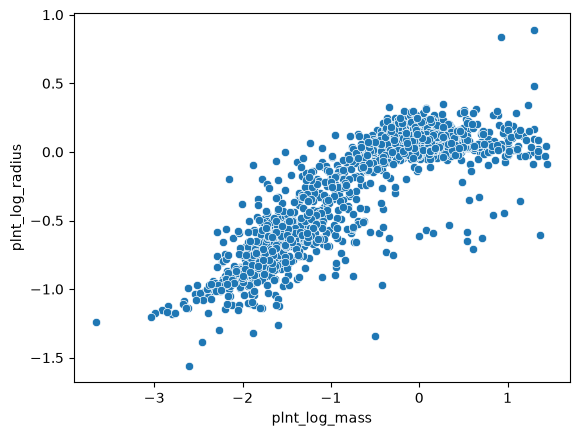

In [48]:
sns.scatterplot(ps, x="plnt_log_mass", y="plnt_log_radius")
plt.show()

Immediately, we can see a much stronger linear relationship, though it seemingly plateaus at the upper end. Let's get the new Pearson correlation coefficient.

In [49]:
print(ps["plnt_log_radius"].corr(ps["plnt_log_mass"]))

0.8648775236026442


This is a significantly stronger positive correlation, which matches our prior observations.

## Star Radius vs. Star Mass

We saw in the **Distributions** section that star radii and star mass are also similar. In the `ps` dataset, we see that they have a pretty strong correlation coefficient (0.43). However, that may be due to duplicate entries. Let's instead look at the heatmap of the `stars` dataset, the indexed DataFrame we made that contains star information and removes duplicate star entries.

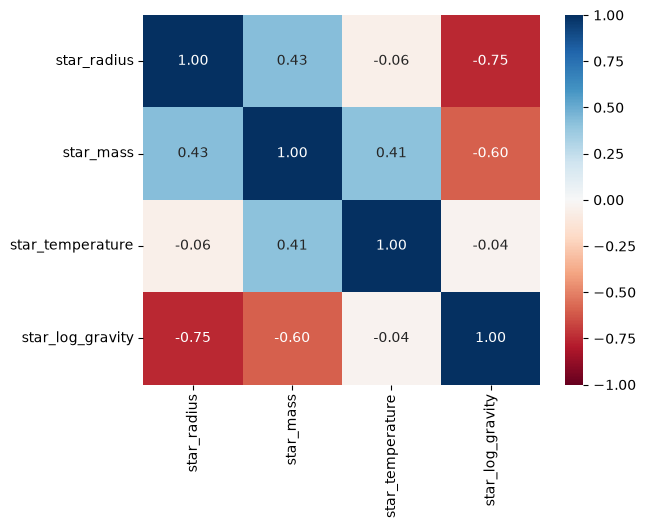

In [50]:
sns.heatmap(stars.corr(numeric_only=True), cmap="RdBu", vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.show()

Nope, the correlation coefficient remained the same, so the relationship is definitely present. However, 0.43 is still a little bit low (\< 0.6), so let's see what it actually looks like on a scatterplot.

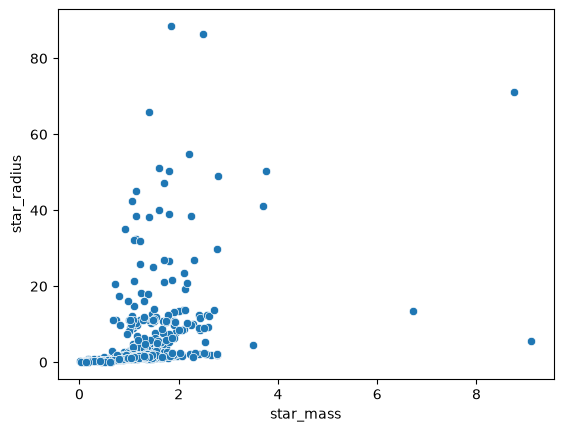

In [51]:
sns.scatterplot(stars, x="star_mass", y="star_radius")
plt.show()

There seems to be an accumulation of data points in the bottom right. However, the presence of outliers way out in the dataset makes it difficult to see what the shape of that accumulation is. Let's zoom in on that range.

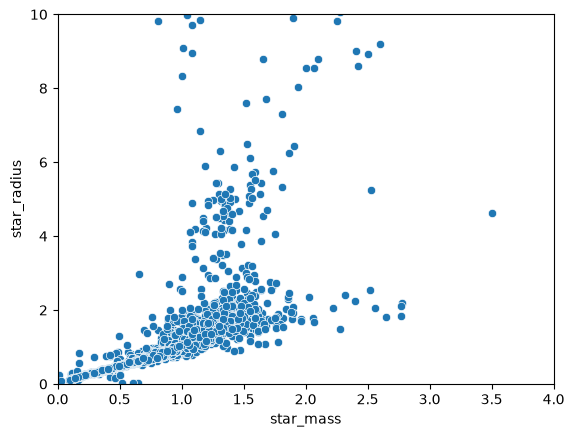

In [52]:
sns.scatterplot(stars, x="star_mass", y="star_radius")
plt.xlim(0, 4)
plt.ylim(0, 10)
plt.show()

That accumulation of points seems very strongly linear. However, there are an excessive amount of points that lie drastically outside of that line.

In the **Distributions** section, we applied logarithmic scaling to the star radius and star mass columns. Let's do the same here.

In [53]:
stars["star_log_radius"] = np.log10(stars["star_radius"])
stars["star_log_mass"] = np.log10(stars["star_mass"])

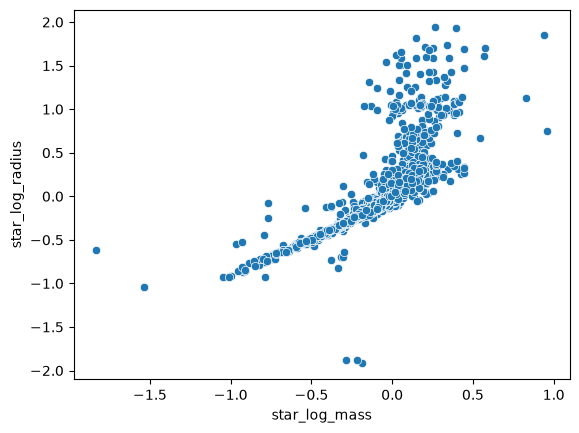

In [54]:
sns.scatterplot(stars, x="star_log_mass", y="star_log_radius")
plt.show()

We get a much more consistent linear relationship, though there is still a large region of points that lies above the line. Let's check what the correlation coefficient of this new relationship is before moving on.

In [55]:
print(stars["star_log_radius"].corr(stars["star_log_mass"]))

0.760073563253829


0.76 is pretty good, but less than that of planet radii and planet masses, which matches what we see in the scatterplot.

Interestingly, both plots seem to follow a strong linear relationship, but deviate towards the upper-right end. While Planet Radius vs. Planet Mass plateaus below the line of best fit, Star Radius vs. Star Mass grows past the line of best fit. Normally, you would expect that the radius vs. mass of celestial bodies would follow a similar distribution, but this doesn't seem to be the case between planets and stars.

## Planet Radius and Planet Mass vs. Planet Orbit Radius (Semi-Major Axis)

In the **Distributions** section, I promised to also investigate this relationship, as it goes against intuition. The heatmap gives a measly 0.09 for Planet Radius vs. Planet Orbit Radius, and a barely better 0.16 for Planet Mass vs. Planet Orbit Radius.

This seems unintuitive at first glance, since gravitational force and thus orbit radius should be proportional to the mass of the planet. By Newton's law of universal gravitation, $F = G \frac{m_1 m_2}{r^2} \implies r^2 = G \frac{m_1 m_2}{F}$, so the planet orbit radius squared should be proportional to the planet mass. However, that's ignoring the fact that $F$ itself is proportional to the planet's mass. Therefore, we end up with $r^2 = G \frac{m_1 m_2}{m_2 g} = G \frac{m_1}{g}$, where $g$ is the gravitational acceleration.

We may be able to approximate this gravitational acceleration by the surface gravity of the star, and therefore the planet's orbit radius has everything to do with the star, and nothing to do with the planet. The only reason different planets have different orbit radii is due to their initial velocities in entering the star system.

Let's try to verify that the relationship described above holds in our data. We should plot $r^2$ against $\frac{m_1}{g}$, all of which we have data for, but not quite in the right format. Our dataset has $r$ (`plnt_orbit_radius`), $m_1$ (`star_mass`), and $\log_{10}(g)$ (`star_log_gravity`). Let's fix that.

In [56]:
ps["plnt_sq_orbit_radius"] = ps["plnt_orbit_radius"] ** 2
ps["star_gravity"] = 10 ** ps["star_log_gravity"]
ps["star_mass_over_log_g"] = ps["star_mass"] / ps["star_log_gravity"]

Now, let's check the correlation coefficient.

In [57]:
print(ps["plnt_sq_orbit_radius"].corr(ps["star_mass_over_log_g"]))

-0.0026601290544186413


Oddly enough, the correlation coefficient is almost none. This most likely indicates that using surface gravitational acceleration as a substitute for a planet's gravitational acceleration is not a good metric. Let's see what this relationship looks like on a scatterplot.

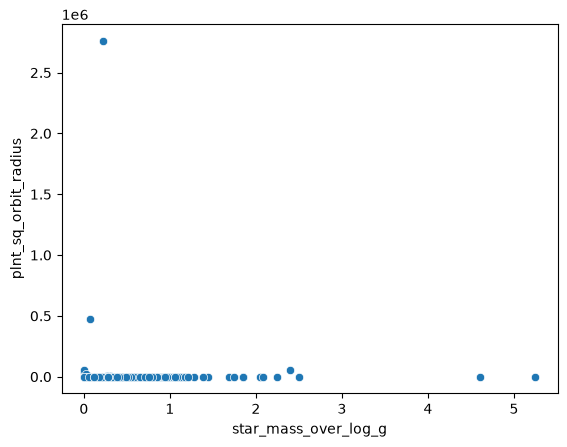

In [58]:
sns.scatterplot(ps, y="plnt_sq_orbit_radius", x="star_mass_over_log_g")
plt.show()

It seems like there are a lot of 0s in our squared orbit radius column. Is something wrong with our data? Let's check.

In [59]:
print((ps["plnt_orbit_radius"] == 0).sum())
print((ps["plnt_sq_orbit_radius"] == 0).sum())

0
0


No, it seems like the data is accurate and there are no errors of values getting clamped to 0. Let's zoom in on our scatterplot.

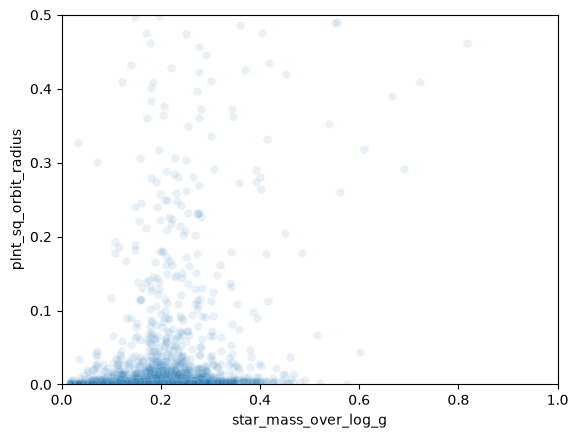

In [60]:
sns.scatterplot(ps, y="plnt_sq_orbit_radius", x="star_mass_over_log_g", alpha=0.1)
plt.xlim(0, 1)
plt.ylim(0, 0.5)
plt.show()

We set `alpha=0.1` to get a better sense of where values are accumulating. It seems like there is no clear relationship, and data points are all over the place. This likely indicates that it was wrong to approximate the gravitational acceleration as the star's surface gravitational acceleration; that only works for measurements close to the surface, like physical experiments performed near Earth's surface.